## 1. Import Libraries

In [43]:
! pip install xgboost


In [44]:
! pip install lightgbm[dask]


In [45]:
! pip install shap


In [46]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import shap
import joblib

## 2. Load KDDTrain+ and KDDTest+

In [47]:
train_df = pd.read_csv(r"E:\BRM003-ML-Project\dataset folder\archive\nsl-kdd\KDDTrain+.txt", header=None)
test_df = pd.read_csv(r"E:\BRM003-ML-Project\dataset folder\archive\nsl-kdd\KDDTest+.txt", header=None)

## 3. Add Column Names

In [48]:
columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "attack_type", "difficulty"
]

train_df.columns = columns
test_df.columns = columns

## 4. Dataset Overview

In [49]:
train_df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack_type,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [50]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  str    
 2   service                      125973 non-null  str    
 3   flag                         125973 non-null  str    
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised              125973 non-null  int64  
 13  root_shell

In [51]:
train_df.shape

(125973, 43)

In [52]:
train_df.dtypes.value_counts()

int64      24
float64    15
str         4
Name: count, dtype: int64

## 5. Data Quality

In [53]:
train_df.isnull().sum().sort_values(ascending=False)

duration                       0
protocol_type                  0
service                        0
flag                           0
src_bytes                      0
dst_bytes                      0
land                           0
wrong_fragment                 0
urgent                         0
hot                            0
num_failed_logins              0
logged_in                      0
num_compromised                0
root_shell                     0
su_attempted                   0
num_root                       0
num_file_creations             0
num_shells                     0
num_access_files               0
num_outbound_cmds              0
is_host_login                  0
is_guest_login                 0
count                          0
srv_count                      0
serror_rate                    0
srv_serror_rate                0
rerror_rate                    0
srv_rerror_rate                0
same_srv_rate                  0
diff_srv_rate                  0
srv_diff_h

In [54]:
test_df.isnull().sum().sum()

np.int64(0)

In [55]:
train_df.duplicated().sum()

np.int64(0)

## 6. Exploratory Data Analysis

In [56]:
train_df["attack_type"].value_counts()

attack_type
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64

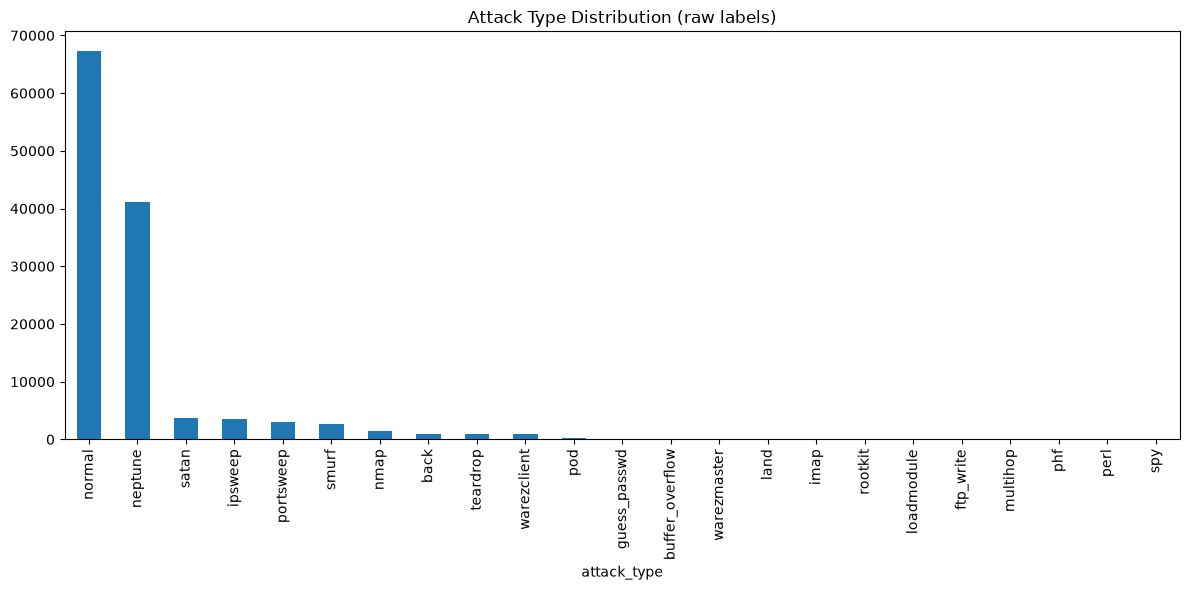

In [57]:
plt.figure(figsize=(12, 6))
train_df["attack_type"].value_counts().plot(kind="bar")
plt.title("Attack Type Distribution (raw labels)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 7. Define Target (Binary)

In [58]:
train_df["label"] = train_df["attack_type"].apply(lambda x: 0 if x == "normal" else 1)
test_df["label"] = test_df["attack_type"].apply(lambda x: 0 if x == "normal" else 1)

train_df["label"].value_counts()

label
0    67343
1    58630
Name: count, dtype: int64

## 8. X / y Separation

In [59]:
X = train_df.drop(columns=["attack_type", "label", "difficulty"])
y = train_df["label"]

X_test_raw = test_df.drop(columns=["attack_type", "label", "difficulty"])
y_test = test_df["label"]

## 9. Identify Data Types

In [60]:
categorical_cols = X.select_dtypes(include=["object"]).columns
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns

print("Categorical columns:", list(categorical_cols))
print("Numerical columns:", list(numerical_cols))

Categorical columns: ['protocol_type', 'service', 'flag']
Numerical columns: ['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']


C:\Users\Surya\AppData\Local\Temp\ipykernel_22504\3553609150.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object"]).columns


## 10. Encode Categorical Features

In [61]:
X = pd.get_dummies(X, columns=categorical_cols, drop_first=False)

# Encode the test set the same way, then align columns to the training set
# (any category seen only in test gets dropped; any missing dummy column is added as 0)
X_test_raw = pd.get_dummies(X_test_raw, columns=categorical_cols, drop_first=False)
X_test_raw = X_test_raw.reindex(columns=X.columns, fill_value=0)

## 11. Train / Validation Split

In [62]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## 12. Feature Scaling

In [63]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# Scale the held-out KDDTest+ set with the SAME scaler (fit only on training data)
X_test_scaled = scaler.transform(X_test_raw)

## 13. Handle Class Imbalance

**Fix:** the original notebook computed `X_train_resampled`/`y_train_resampled` with SMOTE but then trained every model on the plain `X_train_scaled` instead — the balancing was never actually used. SMOTE is now applied to the *scaled* training data, and the resampled set is what every model below is trained on.

In [64]:
pd.Series(y_train).value_counts()

label
0    53874
1    46904
Name: count, dtype: int64

In [65]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

pd.Series(y_train_resampled).value_counts()

label
0    53874
1    53874
Name: count, dtype: int64

## 14. Baseline Models

In [66]:
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}

results = {}
fitted_models = {}

for name, clf in baseline_models.items():
    clf.fit(X_train_resampled, y_train_resampled)
    y_pred = clf.predict(X_val_scaled)

    results[name] = {
        "accuracy": accuracy_score(y_val, y_pred),
        "f1": f1_score(y_val, y_pred),
    }
    fitted_models[name] = clf

    print(f"=== {name} ===")
    print(f"Accuracy: {results[name]['accuracy']:.4f}  |  F1: {results[name]['f1']:.4f}")
    print(classification_report(y_val, y_pred, target_names=["normal", "attack"]))

=== Logistic Regression ===
Accuracy: 0.9733  |  F1: 0.9712
              precision    recall  f1-score   support

      normal       0.97      0.98      0.98     13469
      attack       0.98      0.97      0.97     11726

    accuracy                           0.97     25195
   macro avg       0.97      0.97      0.97     25195
weighted avg       0.97      0.97      0.97     25195

=== Decision Tree ===
Accuracy: 0.9985  |  F1: 0.9984
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00     13469
      attack       1.00      1.00      1.00     11726

    accuracy                           1.00     25195
   macro avg       1.00      1.00      1.00     25195
weighted avg       1.00      1.00      1.00     25195

=== Random Forest ===
Accuracy: 0.9990  |  F1: 0.9989
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00     13469
      attack       1.00      1.00      1.00     11726

    accuracy  

## 15. Advanced Models (XGBoost, LightGBM)

In [67]:
advanced_models = {
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=200,
        max_depth=-1,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    ),
}

for name, clf in advanced_models.items():
    clf.fit(X_train_resampled, y_train_resampled)
    y_pred = clf.predict(X_val_scaled)

    results[name] = {
        "accuracy": accuracy_score(y_val, y_pred),
        "f1": f1_score(y_val, y_pred),
    }
    fitted_models[name] = clf

    print(f"=== {name} ===")
    print(f"Accuracy: {results[name]['accuracy']:.4f}  |  F1: {results[name]['f1']:.4f}")
    print(classification_report(y_val, y_pred, target_names=["normal", "attack"]))

=== XGBoost ===
Accuracy: 0.9992  |  F1: 0.9991
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00     13469
      attack       1.00      1.00      1.00     11726

    accuracy                           1.00     25195
   macro avg       1.00      1.00      1.00     25195
weighted avg       1.00      1.00      1.00     25195

=== LightGBM ===
Accuracy: 0.9994  |  F1: 0.9993
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00     13469
      attack       1.00      1.00      1.00     11726

    accuracy                           1.00     25195
   macro avg       1.00      1.00      1.00     25195
weighted avg       1.00      1.00      1.00     25195



### Soft-Voting Ensemble (Random Forest + XGBoost + LightGBM)

Combines the three tree-based models via soft voting, matching the ensemble strategy used in the base-paper comparison (RF / XGBoost / LightGBM, stacking / soft-voting).

In [68]:
voting_clf = VotingClassifier(
    estimators=[
        ("rf", fitted_models["Random Forest"]),
        ("xgb", fitted_models["XGBoost"]),
        ("lgbm", fitted_models["LightGBM"]),
    ],
    voting="soft",
)

voting_clf.fit(X_train_resampled, y_train_resampled)
y_pred_voting = voting_clf.predict(X_val_scaled)

results["Voting Ensemble (RF+XGB+LGBM)"] = {
    "accuracy": accuracy_score(y_val, y_pred_voting),
    "f1": f1_score(y_val, y_pred_voting),
}
fitted_models["Voting Ensemble (RF+XGB+LGBM)"] = voting_clf

print("=== Voting Ensemble (RF + XGBoost + LightGBM) ===")
print(classification_report(y_val, y_pred_voting, target_names=["normal", "attack"]))

=== Voting Ensemble (RF + XGBoost + LightGBM) ===
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00     13469
      attack       1.00      1.00      1.00     11726

    accuracy                           1.00     25195
   macro avg       1.00      1.00      1.00     25195
weighted avg       1.00      1.00      1.00     25195



In [69]:
pd.DataFrame(results).T.sort_values("f1", ascending=False)

,accuracy,f1
Voting Ensemble (RF+XGB+LGBM),0.999405,0.999360
LightGBM,0.999365,0.999318
XGBoost,0.999167,0.999105
Random Forest,0.998968,0.998891
Decision Tree,0.998531,0.998422
Logistic Regression,0.973328,0.971221


## 16. Hyperparameter Tuning

Lightweight `RandomizedSearchCV` on the best-performing tree model (Random Forest) as an example — extend the grid / swap in XGBoost or LightGBM the same way if you want to tune those instead.

In [70]:
param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=10,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=-1,
)

rf_search.fit(X_train_resampled, y_train_resampled)

print("Best params:", rf_search.best_params_)
print("Best CV F1:", rf_search.best_score_)

best_rf = rf_search.best_estimator_
fitted_models["Random Forest (tuned)"] = best_rf

Best params: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 30}
Best CV F1: 0.9985601719941885


## 17. Feature Importance

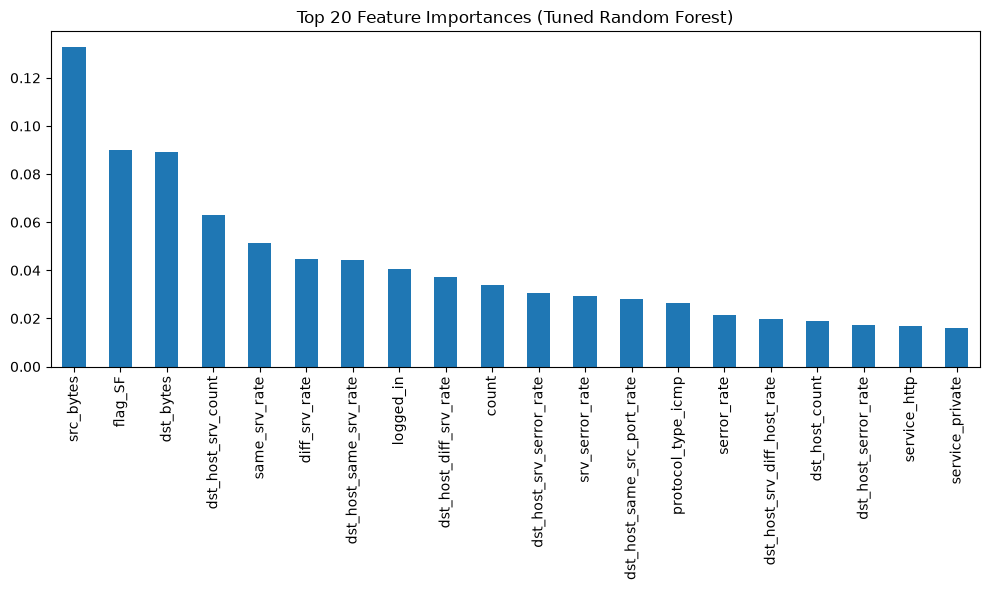

In [71]:
importance = pd.Series(
    best_rf.feature_importances_,
    index=X_train.columns
)

importance.sort_values(ascending=False).head(20).plot(
    kind="bar",
    figsize=(10, 6),
    title="Top 20 Feature Importances (Tuned Random Forest)"
)

plt.tight_layout()
plt.show()

## 18. SHAP Explainability

Uses `TreeExplainer` on the tuned Random Forest (works identically for XGBoost / LightGBM — just swap the model passed in). A small sample of the validation set is used for speed.

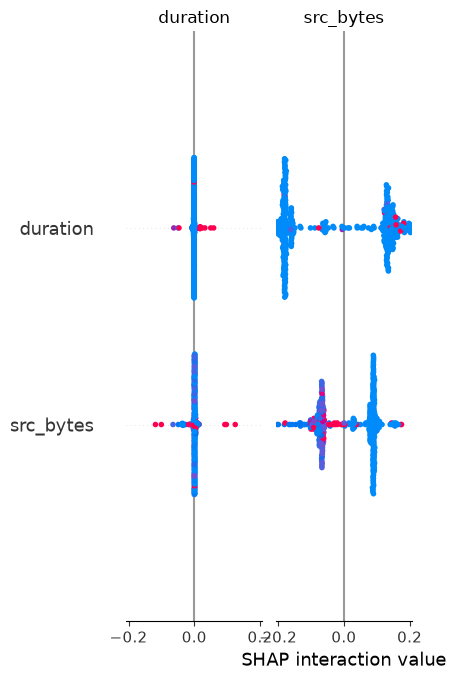

In [72]:
explainer = shap.TreeExplainer(best_rf)

shap_sample = pd.DataFrame(X_val_scaled, columns=X_train.columns).sample(
    n=min(500, len(X_val)), random_state=42
)

shap_values = explainer.shap_values(shap_sample)

# For a binary classifier, shap_values is a list [class_0, class_1] in older SHAP versions,
# or a single (n_samples, n_features) array for class 1 in newer ones — handle both.
sv_attack = shap_values[1] if isinstance(shap_values, list) else shap_values

shap.summary_plot(sv_attack, shap_sample, show=True)

## 19. Model Evaluation

**Fix:** evaluation is now run explicitly for the chosen best model on the validation set (`y_val` / `X_val_scaled`), instead of silently reusing whatever `y_pred` happened to be left over from an earlier loop.

In [73]:
best_model_name = pd.DataFrame(results).T["f1"].idxmax()
best_model = fitted_models[best_model_name]
print("Best model on validation set:", best_model_name)

y_pred_best = best_model.predict(X_val_scaled)

print(classification_report(y_val, y_pred_best, target_names=["normal", "attack"]))

Best model on validation set: Voting Ensemble (RF+XGB+LGBM)
              precision    recall  f1-score   support

      normal       1.00      1.00      1.00     13469
      attack       1.00      1.00      1.00     11726

    accuracy                           1.00     25195
   macro avg       1.00      1.00      1.00     25195
weighted avg       1.00      1.00      1.00     25195



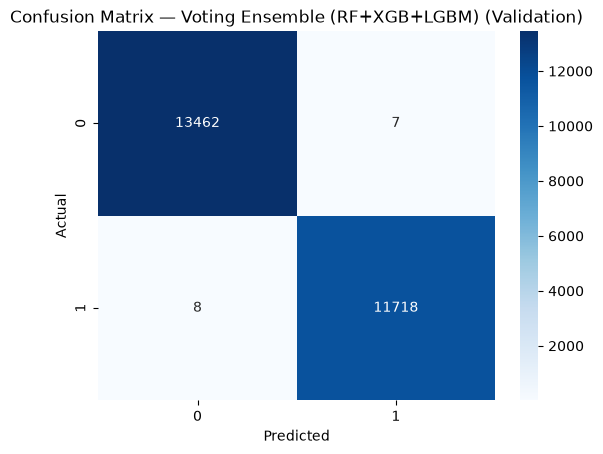

In [74]:
cm = confusion_matrix(y_val, y_pred_best)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {best_model_name} (Validation)")
plt.show()

In [75]:
prob_val = best_model.predict_proba(X_val_scaled)[:, 1]
auc_val = roc_auc_score(y_val, prob_val)
print("Validation ROC-AUC:", auc_val)

Validation ROC-AUC: 0.9999961503757936


## 20. Final Evaluation on KDDTest+

**Fix:** the original notebook built `X_test_scaled` / `y_test` but never used them. This is the true held-out test evaluation.

In [76]:
y_pred_test = best_model.predict(X_test_scaled)
prob_test = best_model.predict_proba(X_test_scaled)[:, 1]

print(f"=== {best_model_name} — KDDTest+ (held-out) ===")
print(classification_report(y_test, y_pred_test, target_names=["normal", "attack"]))
print("Test ROC-AUC:", roc_auc_score(y_test, prob_test))

=== Voting Ensemble (RF+XGB+LGBM) — KDDTest+ (held-out) ===
              precision    recall  f1-score   support

      normal       0.67      0.97      0.80      9711
      attack       0.97      0.64      0.77     12833

    accuracy                           0.79     22544
   macro avg       0.82      0.81      0.79     22544
weighted avg       0.84      0.79      0.78     22544

Test ROC-AUC: 0.9668595037429528


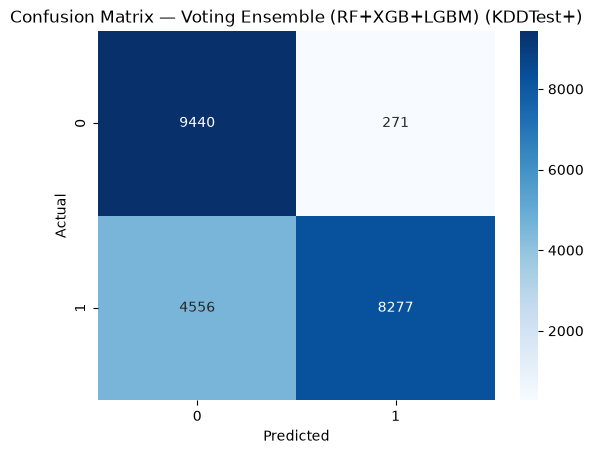

In [77]:
cm_test = confusion_matrix(y_test, y_pred_test)

sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {best_model_name} (KDDTest+)")
plt.show()

## 21. Save Model

In [78]:
joblib.dump(best_model, "best_model.joblib")
joblib.dump(scaler, "scaler.joblib")
joblib.dump(list(X_train.columns), "feature_columns.joblib")

print(f"Saved '{best_model_name}' to best_model.joblib, plus scaler.joblib and feature_columns.joblib")

Saved 'Voting Ensemble (RF+XGB+LGBM)' to best_model.joblib, plus scaler.joblib and feature_columns.joblib
